<a href="https://www.kaggle.com/code/lalit7881/credit-card-fraud-detection-94-51?scriptVersionId=374247063" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

# CatBoost
from catboost import CatBoostClassifier

# LightGBM
from lightgbm import LGBMClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# Class Imbalance Handling
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Hyperparameter Optimization
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Statistical Analysis
from scipy import stats

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.6f}'.format)

# Visualization Settings
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

print("All libraries imported successfully!")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

All libraries imported successfully!
/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e11/train.csv
/kaggle/input/competitions/playground-series-s6e11/test.csv


## Loading dataset

In [2]:
import pandas as pd

# Dataset paths
DATA_PATH = "/kaggle/input/competitions/playground-series-s6e11/"

# Load datasets
train = pd.read_csv(DATA_PATH + "train.csv")
test = pd.read_csv(DATA_PATH + "test.csv")
sample = pd.read_csv(DATA_PATH + "sample_submission.csv")

# Dataset overview
print("TRAIN SHAPE:", train.shape)
print("TEST SHAPE:", test.shape)

print("\nTRAIN COLUMNS:")
print(train.columns.tolist())

print("\nSAMPLE SUBMISSION:")
print(sample.head())

print("\nMISSING VALUES:")
print(train.isnull().sum())

print("\nFIRST 5 TRAINING ROWS:")
display(train.head())

TRAIN SHAPE: (699960, 26)
TEST SHAPE: (299984, 25)

TRAIN COLUMNS:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud']

SAMPLE SUBMISSION:
       id  is_fraud
0  699960  0.016700
1  699961  0.016700
2  699962  0.016700
3  699963  0.016700
4  699964  0.016700

MISSING VALUES:
id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_cou

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.160000,9.770000,1,17.780000,48,56,1269.350000,0,5.500000,17,3,29.200000,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.000000
1,1,24.830000,1.540000,3,13.060000,38,28,3233.000000,0,33.400000,23,5,29.900000,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.000000
2,2,6.360000,1.200000,4,8.170000,50,55,1046.880000,0,35.800000,15,0,24.100000,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.000000
3,3,37.440000,5.130000,4,8.670000,48,48,2217.670000,0,20.700000,7,3,41.900000,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.000000
4,4,653.850000,0.800000,4,11.690000,37,52,3291.060000,0,34.800000,4,4,48.000000,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.000000


## EDA

FRAUD DISTRIBUTION
is_fraud
0.000000    688271
1.000000     11689
Name: count, dtype: int64

FRAUD PERCENTAGES
is_fraud
0.000000   98.330000
1.000000    1.670000
Name: proportion, dtype: float64


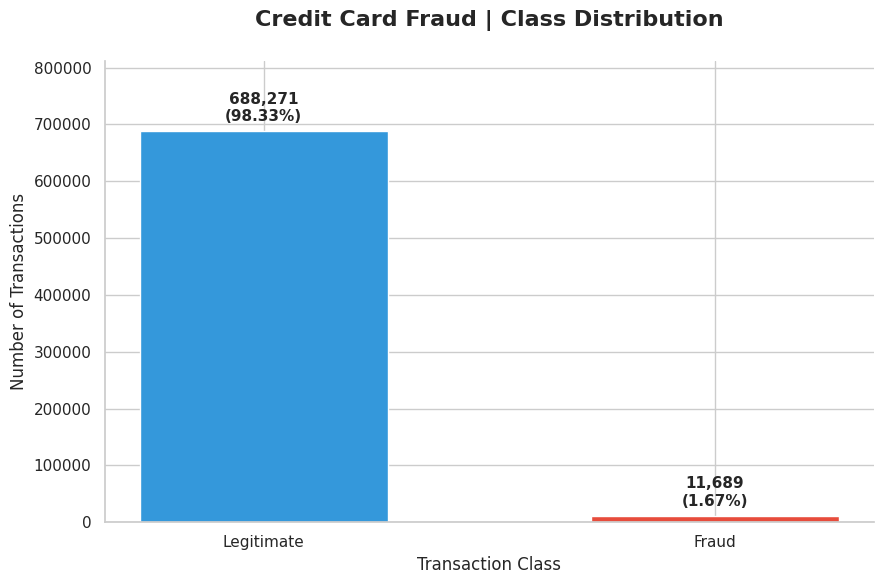

In [3]:
# Fraud distribution
counts = train["is_fraud"].value_counts().sort_index()
percentages = train["is_fraud"].value_counts(
    normalize=True
).sort_index() * 100

print("FRAUD DISTRIBUTION")
print(counts)
print("\nFRAUD PERCENTAGES")
print(percentages.round(2))

# Clean professional chart
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 6))

colors = ["#3498db", "#e74c3c"]
labels = ["Legitimate", "Fraud"]

bars = ax.bar(
    labels,
    counts.values,
    color=colors,
    width=0.55
)

# Labels inside bars
for bar, count, pct in zip(
    bars, counts.values, percentages.values
):
    ax.annotate(
        f"{count:,}\n({pct:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2,
            bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Credit Card Fraud | Class Distribution",
    fontsize=16,
    fontweight="bold",
    pad=25
)

ax.set_ylabel("Number of Transactions")
ax.set_xlabel("Transaction Class")
ax.set_ylim(0, counts.max() * 1.18)

sns.despine()
plt.tight_layout()
plt.show()

## 

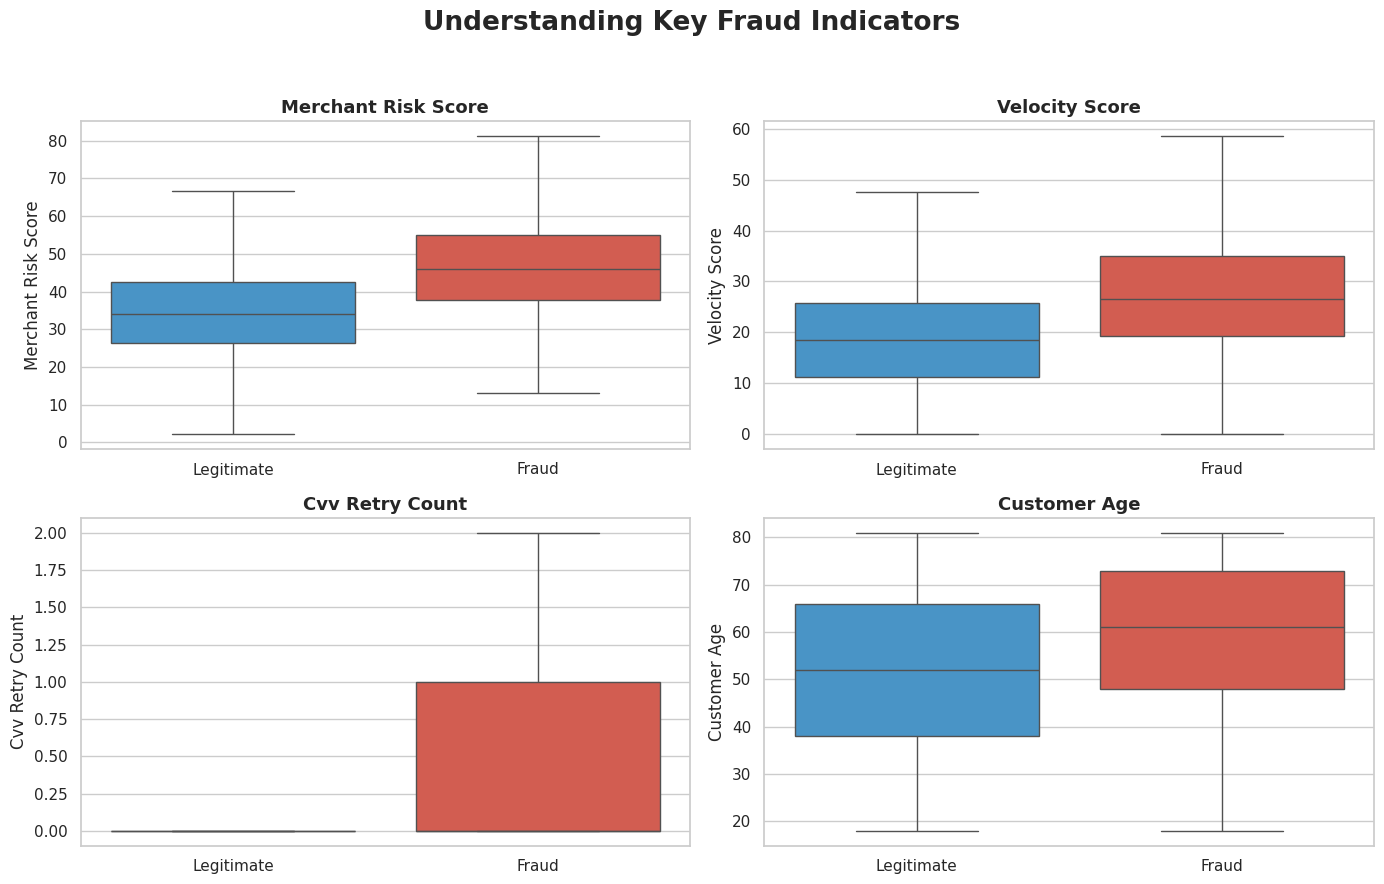

In [4]:
sns.set_theme(style="whitegrid")

features = [
    "merchant_risk_score",
    "velocity_score",
    "cvv_retry_count",
    "customer_age"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(features, axes.flatten()):

    sns.boxplot(
        data=train,
        x="is_fraud",
        y=feature,
        hue="is_fraud",
        palette=["#3498db", "#e74c3c"],
        legend=False,
        showfliers=False,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Legitimate", "Fraud"])
    ax.set_xlabel("")
    ax.set_ylabel(feature.replace("_", " ").title())

fig.suptitle(
    "Understanding Key Fraud Indicators",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Feature engineering

In [5]:
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Separate features and target
X = train.drop(columns=["id", "is_fraud"])
y = train["is_fraud"].astype(int)

# Identify categorical features
cat_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Convert categorical columns to strings
for col in cat_features:
    X[col] = X[col].astype(str)

print("Categorical features:", cat_features)

# Stratified validation split
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# CatBoost baseline model
model = CatBoostClassifier(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=4
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=60
)

# Predict validation probabilities
valid_preds = model.predict_proba(X_valid)[:, 1]

# Evaluate
auc = roc_auc_score(y_valid, valid_preds)

print("\n" + "=" * 40)
print(f"VALIDATION ROC-AUC: {auc:.6f}")
print(f"BEST ITERATION: {model.best_iteration_}")
print("=" * 40)


Categorical features: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
0:	test: 0.8219597	best: 0.8219597 (0)	total: 596ms	remaining: 5m 57s
100:	test: 0.9375097	best: 0.9375097 (100)	total: 44.5s	remaining: 3m 39s
200:	test: 0.9412978	best: 0.9412978 (200)	total: 1m 26s	remaining: 2m 52s
300:	test: 0.9425497	best: 0.9425521 (299)	total: 2m 8s	remaining: 2m 7s
400:	test: 0.9431669	best: 0.9431707 (397)	total: 2m 49s	remaining: 1m 24s
500:	test: 0.9434746	best: 0.9434746 (500)	total: 3m 32s	remaining: 41.9s
599:	test: 0.9437056	best: 0.9437056 (599)	total: 4m 14s	remaining: 0us

bestTest = 0.9437055818
bestIteration = 599


VALIDATION ROC-AUC: 0.943706
BEST ITERATION: 599


TOP 15 IMPORTANT FEATURES


,Feature,Importance
11,merchant_risk_score,25.808837
8,velocity_score,20.805041
7,cvv_retry_count,10.252891
15,auth_method,10.011460
5,customer_age,9.914374
19,is_new_merchant,6.713272
21,ip_country_mismatch,2.357686
2,txn_count_last_24h,1.962444
20,used_vpn,1.872814
22,billing_shipping_mismatch,1.798002


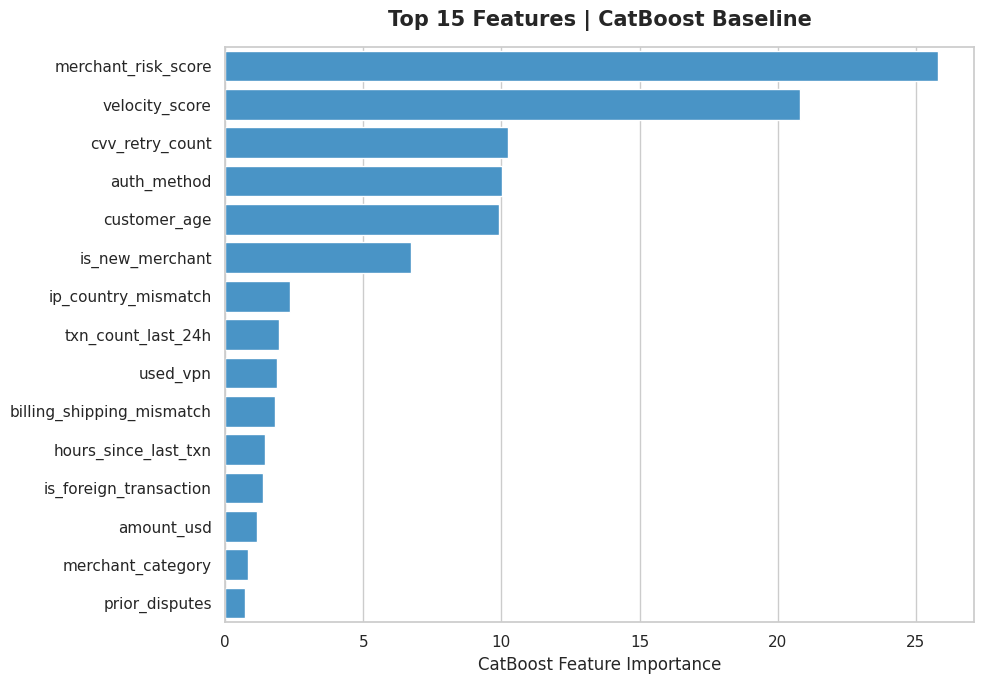

In [6]:
# Extract feature importance from trained CatBoost
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.get_feature_importance()
}).sort_values("Importance", ascending=False)

print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15))

# Visualize the top 15 features
top_features = importance_df.head(15)

fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="#3498db",
    ax=ax
)

ax.set_title(
    "Top 15 Features | CatBoost Baseline",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("CatBoost Feature Importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [7]:

import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
# Load dataset independently
DATA_PATH = "/kaggle/input/competitions/playground-series-s6e11/"

train = pd.read_csv(DATA_PATH + "train.csv")

print("Dataset loaded:", train.shape)

# Original features (without engineered features)
X_lgb = train.drop(columns=["id", "is_fraud"]).copy()
y_lgb = train["is_fraud"].astype(int)

# LightGBM supports pandas categorical columns
categorical_cols = X_lgb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    X_lgb[col] = X_lgb[col].astype("category")

# Same stratified validation split as V1
X_train_lgb, X_valid_lgb, y_train_lgb, y_valid_lgb = (
    train_test_split(
        X_lgb,
        y_lgb,
        test_size=0.20,
        random_state=42,
        stratify=y_lgb
    )
)

# LightGBM baseline
model_lgb = lgb.LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.9,
    subsample=0.9,
    subsample_freq=1,
    reg_lambda=3.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

model_lgb.fit(
    X_train_lgb,
    y_train_lgb,
    eval_set=[(X_valid_lgb, y_valid_lgb)],
    eval_metric="auc",
    categorical_feature=categorical_cols,
    callbacks=[
        lgb.early_stopping(100),
        lgb.log_evaluation(200)
    ]
)

# Validation predictions
preds_lgb = model_lgb.predict_proba(
    X_valid_lgb
)[:, 1]

auc_lgb = roc_auc_score(y_valid_lgb, preds_lgb)

# Compare with CatBoost V1
baseline_auc = 0.9437055818

print("\n" + "=" * 45)
print(f"CatBoost V1 ROC-AUC: {baseline_auc:.6f}")
print(f"LightGBM V4 ROC-AUC: {auc_lgb:.6f}")
print(f"Improvement:         {auc_lgb - baseline_auc:+.6f}")
print(f"Best Iteration:      {model_lgb.best_iteration_}")
print("=" * 45)

Dataset loaded: (699960, 26)
Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.943387	valid_0's binary_logloss: 0.046808
[400]	valid_0's auc: 0.944897	valid_0's binary_logloss: 0.0461794
Early stopping, best iteration is:
[483]	valid_0's auc: 0.945032	valid_0's binary_logloss: 0.0461152

CatBoost V1 ROC-AUC: 0.943706
LightGBM V4 ROC-AUC: 0.945032
Improvement:         +0.001327
Best Iteration:      483


In [8]:
from sklearn.metrics import roc_auc_score

# Get predictions from both models
cat_preds = model.predict_proba(X_valid)[:, 1]
lgb_preds = model_lgb.predict_proba(X_valid_lgb)[:, 1]

# Ensure validation rows match
assert X_valid.index.equals(X_valid_lgb.index), \
    "Validation rows do not match!"

assert np.array_equal(
    y_valid.to_numpy(),
    y_valid_lgb.to_numpy()
), "Validation labels do not match!"

# Try different LightGBM weights
results = []

for lgb_weight in [0.0, 0.25, 0.50, 0.75, 1.0]:
    cat_weight = 1.0 - lgb_weight

    blended_preds = (
        cat_weight * cat_preds +
        lgb_weight * lgb_preds
    )

    blend_auc = roc_auc_score(
        y_valid, blended_preds
    )

    results.append({
        "CatBoost Weight": cat_weight,
        "LightGBM Weight": lgb_weight,
        "Validation ROC-AUC": blend_auc
    })

# Display comparison
results_df = pd.DataFrame(results).sort_values(
    "Validation ROC-AUC",
    ascending=False
)

print("VERSION 5 — BLENDING RESULTS")
display(results_df)

best = results_df.iloc[0]

print("\nBEST BLEND")
print(f"CatBoost Weight: {best['CatBoost Weight']:.2f}")
print(f"LightGBM Weight: {best['LightGBM Weight']:.2f}")
print(f"Validation ROC-AUC: {best['Validation ROC-AUC']:.6f}")
print(
    f"Improvement vs LightGBM: "
    f"{best['Validation ROC-AUC'] - auc_lgb:+.6f}"
)

VERSION 5 — BLENDING RESULTS


,CatBoost Weight,LightGBM Weight,Validation ROC-AUC
3,0.250000,0.750000,0.945196
4,0.000000,1.000000,0.945032
2,0.500000,0.500000,0.945017
1,0.750000,0.250000,0.944538
0,1.000000,0.000000,0.943706



BEST BLEND
CatBoost Weight: 0.25
LightGBM Weight: 0.75
Validation ROC-AUC: 0.945196
Improvement vs LightGBM: +0.000163


In [9]:
DATA_PATH = "/kaggle/input/competitions/playground-series-s6e11/"

test_v5 = pd.read_csv(DATA_PATH + "test.csv")
sample_v5 = pd.read_csv(DATA_PATH + "sample_submission.csv")

# Prepare test features for CatBoost
X_test_cat = test_v5.drop(columns=["id"]).copy()

for col in cat_features:
    X_test_cat[col] = X_test_cat[col].astype(str)

# Prepare test features for LightGBM
X_test_lgb = test_v5.drop(columns=["id"]).copy()

for col in categorical_cols:
    X_test_lgb[col] = pd.Categorical(
        X_test_lgb[col],
        categories=X_train_lgb[col].cat.categories
    )

# Generate probabilities from both models
cat_test_preds = model.predict_proba(X_test_cat)[:, 1]
lgb_test_preds = model_lgb.predict_proba(X_test_lgb)[:, 1]

# Weighted ensemble: 25% CatBoost + 75% LightGBM
blend_test_preds = (
    0.25 * cat_test_preds +
    0.75 * lgb_test_preds
)

# Create submission
submission_v5 = sample_v5.copy()
submission_v5["is_fraud"] = blend_test_preds

# Validate output
assert test_v5["id"].equals(sample_v5["id"])
assert submission_v5.shape == (len(test_v5), 2)
assert submission_v5["id"].equals(sample_v5["id"])
assert np.isfinite(submission_v5["is_fraud"]).all()
assert submission_v5["is_fraud"].between(0, 1).all()

# Save Version 5 submission
submission_v5.to_csv(
    "/kaggle/working/submission_blend_v5.csv",
    index=False
)

print("Version 5 submission created successfully!")
print("Shape:", submission_v5.shape)
print(submission_v5.head())
print("File: submission_blend_v5.csv")

Version 5 submission created successfully!
Shape: (299984, 2)
       id  is_fraud
0  699960  0.000231
1  699961  0.000168
2  699962  0.107230
3  699963  0.001392
4  699964  0.001396
File: submission_blend_v5.csv


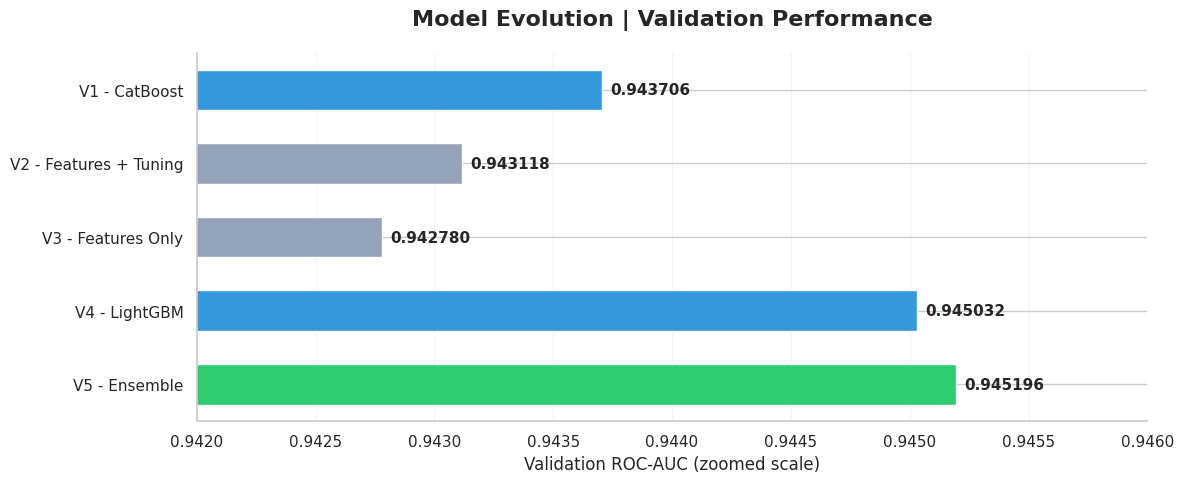

,Model,Validation ROC-AUC
0,V1 - CatBoost,0.943706
1,V2 - Features + Tuning,0.943118
2,V3 - Features Only,0.942780
3,V4 - LightGBM,0.945032
4,V5 - Ensemble,0.945196


In [10]:
# Recorded experimental results
performance = pd.DataFrame({
    "Model": [
        "V1 - CatBoost",
        "V2 - Features + Tuning",
        "V3 - Features Only",
        "V4 - LightGBM",
        "V5 - Ensemble"
    ],
    "Validation ROC-AUC": [
        0.943706,
        0.943118,
        0.942780,
        0.945032,
        0.945196
    ]
})

colors = [
    "#3498db", "#94a3b8", "#94a3b8",
    "#3498db", "#2ecc71"
]

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.barh(
    performance["Model"],
    performance["Validation ROC-AUC"],
    color=colors,
    height=0.55
)

ax.bar_label(
    bars,
    fmt="%.6f",
    padding=6,
    fontsize=11,
    fontweight="bold"
)

ax.set_xlim(0.942, 0.946)
ax.invert_yaxis()

ax.set_title(
    "Model Evolution | Validation Performance",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Validation ROC-AUC (zoomed scale)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

display(performance)

### Conclusion¶
This notebook explores credit card fraud detection through exploratory data analysis, gradient boosting, and ensemble learning.

Key Findings
Only 1.67% of training transactions are fraudulent.
Merchant risk score and velocity score are influential predictive features.
Additional feature engineering did not improve our CatBoost baseline.
LightGBM achieved better validation performance than CatBoost.
Weighted probability averaging achieved the best observed performance.
Final Results
Metric	Score
Baseline Public ROC-AUC	0.94557
Ensemble Validation ROC-AUC	0.945196
Ensemble Public ROC-AUC	0.94619
8. Limitations and Future Improvements
The models were evaluated using a single stratified validation split.
Ensemble weights were selected using the same validation set.
Public leaderboard performance may differ from private leaderboard performance.
V2 and V3 results are recorded from earlier experiments and are not retrained in this notebook.
Potential improvements include:

Stratified K-Fold cross-validation
Out-of-fold ensemble optimization
Automated hyperparameter tuning
Additional feature engineering experiments
Thank You for Reading!
I hope this notebook helps you understand fraud detection, gradient boosting, and ensemble learning.

If you found this notebook helpful, consider leaving an upvote. Feedback and suggestions are always welcome.

Happy Kaggling!